In [25]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from sklearn.model_selection import train_test_split

In [23]:
DATA_PATH = './dataset/'
img_row, img_col = 102, 136
x, y = [], []
classes = os.listdir(DATA_PATH)
print(classes)
counter = 0

['Boot', 'Sandal', 'Shoe']


In [ ]:
for class_path in classes:
    for image_path in os.listdir(f"{DATA_PATH}{class_path}"):
        path = f"{DATA_PATH}{class_path}/{image_path}"
        label = counter
        img = tf.keras.preprocessing.image.load_img(path, target_size=(img_row, img_col))
        img = tf.keras.preprocessing.image.array_to_img(img)
        x.append(img) 
        y.append(label)

    counter += 1

x = np.array(x)
y = np.array(y)
x = x.astype('float32') / 255.0

In [ ]:
# 80: 10 : 10
# 80 ; 10 : 10
x_train, x_temp, y_train, y_temp = train_test_split(
    x, y, test_size=0.2, random_state=42
)
x_test, x_val, y_test, y_val = train_test_split(
    x_temp, y_temp, test_size=0.5, random_state=42067
)

y_train = keras.utils.to_categorical(y_train)
y_test = keras.utils.to_categorical(y_test)
y_val = keras.utils.to_categorical(y_val)
print(x_train.shape)

(1200, 102, 136, 3)


In [36]:
import keras.layers
model = keras.Sequential()

model.add(keras.layers.Conv2D(6, (6,6), activation="relu", input_shape=(img_row, img_col, 3)))
model.add(keras.layers.AveragePooling2D((2,2), 2))

model.add(keras.layers.Conv2D(16, (6,6), activation="relu"))
model.add(keras.layers.AveragePooling2D((2,2), 2))

model.add(keras.layers.Flatten())
model.add(keras.layers.Dense(120, activation="relu"))
model.add(keras.layers.Dense(84, activation="relu"))
model.add(keras.layers.Dense(3, activation="softmax"))

c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=['accuracy']
)

history = model.fit(
    x_train, y_train,
    epochs=10, batch_size=120, validation_data=(x_val, y_val)
)

Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 9s 260ms/step - accuracy: 0.5600 - loss: 1.0601 - val_accuracy: 0.6733 - val_loss: 0.9247
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 145ms/step - accuracy: 0.7450 - loss: 0.6996 - val_accuracy: 0.8000 - val_loss: 0.4366
Epoch 3/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 141ms/step - accuracy: 0.8400 - loss: 0.3826 - val_accuracy: 0.9200 - val_loss: 0.3053
Epoch 4/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 135ms/step - accuracy: 0.9017 - loss: 0.2744 - val_accuracy: 0.9533 - val_loss: 0.1941
Epoch 5/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 138ms/step - accuracy: 0.9283 - loss: 0.2088 - val_accuracy: 0.9600 - val_loss: 0.1504
Epoch 6/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 138ms/step - accuracy: 0.9408 - loss: 0.1694 - val_accuracy: 0.9200 - val_loss: 0.1791
Epoch 7/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 135ms/step - accuracy: 0.9442 - loss: 0.1744 - val_accuracy: 0.9467 - val_loss: 0.1981
Epoch 8/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 140ms/step - accuracy: 0.9475 - loss: 0.1597 - val_accuracy: 0.

In [38]:
model.evaluate(x_test, y_test)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.8867 - loss: 0.2700


[0.2700008451938629, 0.8866666555404663]

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step


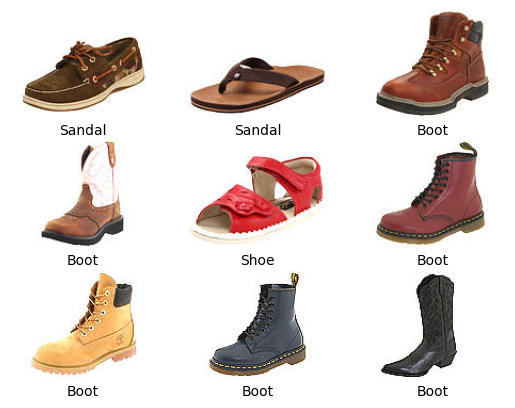

In [39]:
predicition = model.predict(x_test)
predicted_label = np.argmax(predicition, 1)

for i in range(9):
    plt.subplot(3, 3, i+1)
    plt.imshow(x_test[i], cmap='gray')
    plt.axis('off')
    plt.text(
        0.5, -0.15, classes[predicted_label[i]],
        fontsize=10, ha='center',
        transform = plt.gca().transAxes
    )

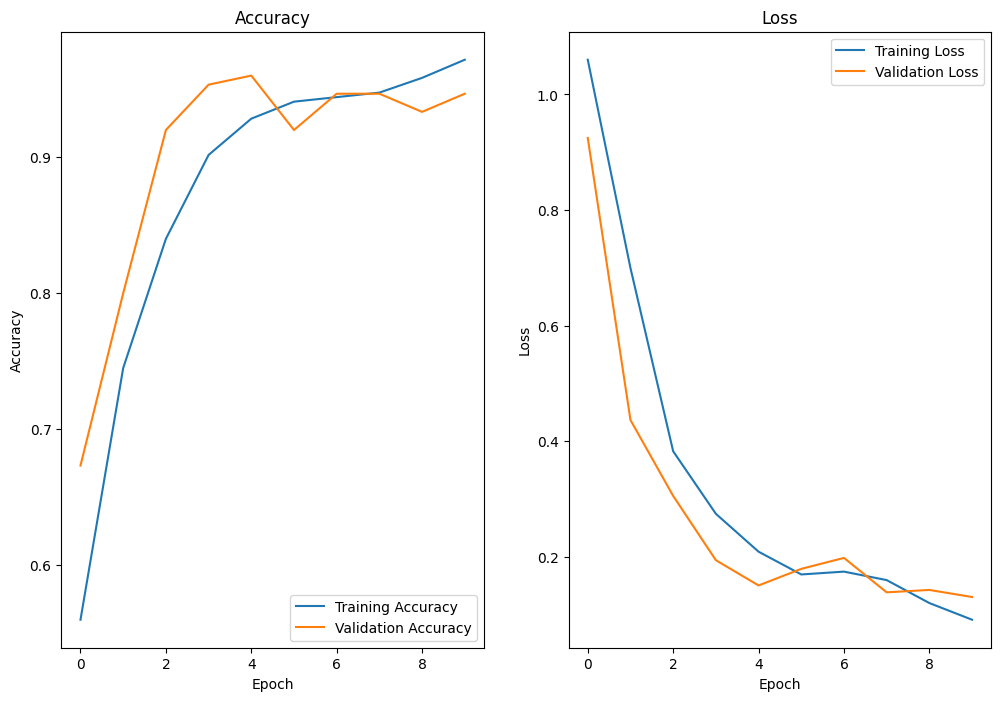

In [41]:
plt.figure(figsize=(12, 8))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label="Training Accuracy")
plt.plot(history.history['val_accuracy'], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label="Training Loss")
plt.plot(history.history['val_loss'], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss")
plt.legend()

plt.show()